# SensorGuard: Multivariate ML Anomaly Detection (Isolation Forest)

## 1. Overview & Motivation
While univariate statistical methods (IQR and Rolling Z-Score) detect spikes in single variables, real-world IoT hardware failures often appear across multiple variables simultaneously (such as a temperature drift combined with an abnormal humidity jump and battery voltage drop).

Here we train an unsupervised **Isolation Forest** per sensor (`moteid`) using a causal 70% chronological split to prevent look-ahead bias, then compare its detections against our statistical baselines.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

# 1. Load the exported dataset
df_ml = pd.read_csv('Data/cleaned_sensor_data.csv')
df_ml['timestamp'] = pd.to_datetime(df_ml['timestamp'])

print(f"Loaded {len(df_ml):,} records across {df_ml['moteid'].nunique()} sensors.")

# 2. Run Causal Per-Sensor Isolation Forest
features = ['temperature', 'humidity', 'light', 'voltage']

def run_isolation_forest(group, contamination=0.02):
    valid_idx = group[features].dropna().index
    result = pd.Series(False, index=group.index)
    
    if len(valid_idx) < 50:
        return result
        
    X = group.loc[valid_idx, features]
    split_point = int(len(X) * 0.7)  # Fit strictly on first 70% to avoid look-ahead bias
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X.iloc[:split_point])
    X_all = scaler.transform(X)
    
    iso = IsolationForest(n_estimators=100, contamination=contamination, random_state=42)
    iso.fit(X_train)
    
    preds = iso.predict(X_all)
    result.loc[valid_idx] = (preds == -1)
    return result

df_ml['anomaly_iforest'] = df_ml.groupby('moteid', group_keys=False).apply(run_isolation_forest)
print(f"Total Multivariate Anomalies Detected by Isolation Forest: {df_ml['anomaly_iforest'].sum():,}")

Loaded 2,303,286 records across 54 sensors.
Total Multivariate Anomalies Detected by Isolation Forest: 76,670


## 2. Visual & Statistical Comparison
We compare anomalies flagged by **Isolation Forest** (multivariate) against our statistical flags and inspect how they align across `temperature` and `voltage` for Mote 1.

,Anomaly / Flag Type,Count,Percentage (%)
0,is_z_anomaly,62828,2.73
1,anomaly_iforest,76670,3.33


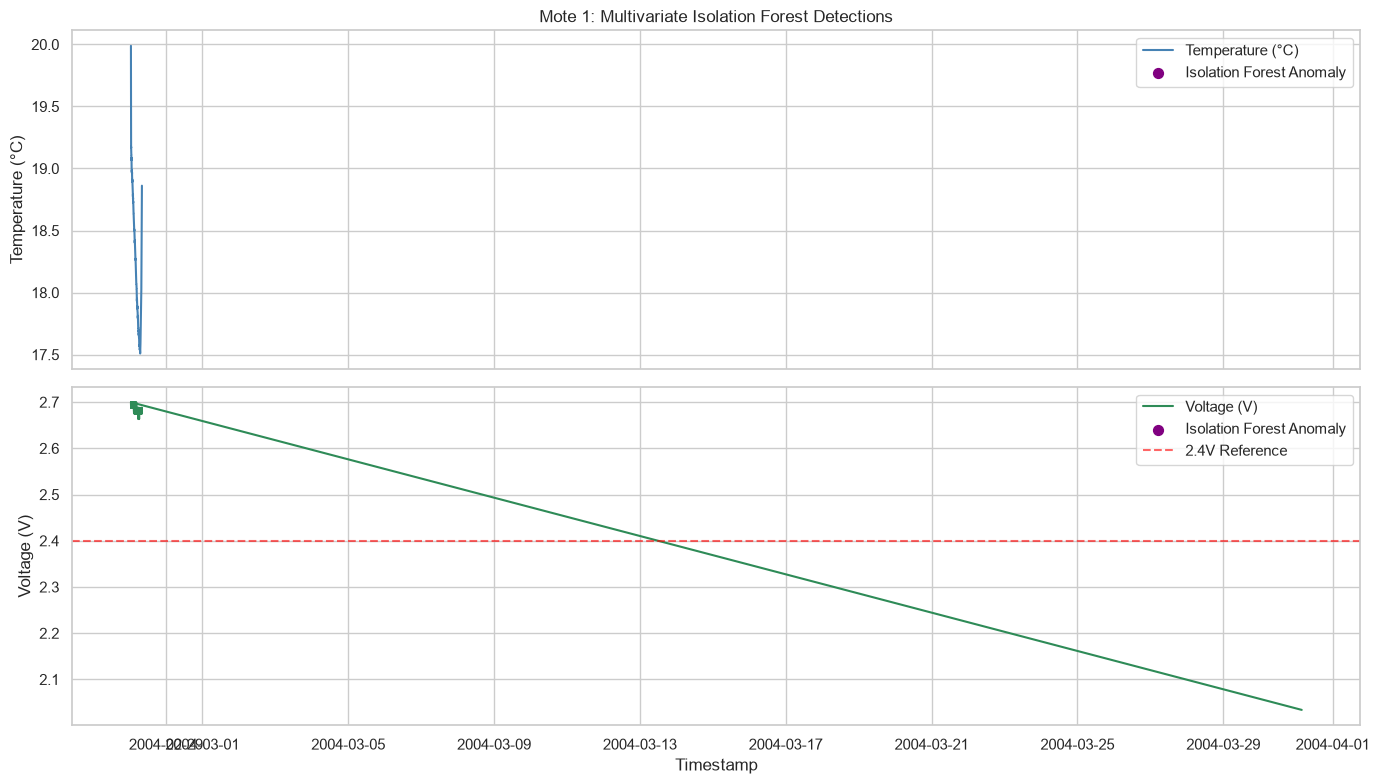

In [2]:
# 1. Summary table of all anomaly/flag columns
anomaly_cols = [col for col in df_ml.columns if 'anomaly' in col or 'flag' in col]
summary = pd.DataFrame({
    'Anomaly / Flag Type': anomaly_cols,
    'Count': [df_ml[col].sum() for col in anomaly_cols],
    'Percentage (%)': [(df_ml[col].mean() * 100).round(2) for col in anomaly_cols]
})
display(summary)

# 2. Plot Mote 1 multivariate detections
sample_mote = 1
mote_df = df_ml[df_ml['moteid'] == sample_mote].iloc[:300]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(mote_df['timestamp'], mote_df['temperature'], color='steelblue', label='Temperature (°C)')
if_anom = mote_df[mote_df['anomaly_iforest']]
axes[0].scatter(if_anom['timestamp'], if_anom['temperature'], color='purple', label='Isolation Forest Anomaly', s=50, zorder=5)
axes[0].set_ylabel('Temperature (°C)')
axes[0].set_title(f'Mote {sample_mote}: Multivariate Isolation Forest Detections')
axes[0].legend()

axes[1].plot(mote_df['timestamp'], mote_df['voltage'], color='seagreen', label='Voltage (V)')
axes[1].scatter(if_anom['timestamp'], if_anom['voltage'], color='purple', label='Isolation Forest Anomaly', s=50, zorder=5)
axes[1].axhline(2.4, color='red', linestyle='--', alpha=0.6, label='2.4V Reference')
axes[1].set_ylabel('Voltage (V)')
axes[1].set_xlabel('Timestamp')
axes[1].legend()

plt.tight_layout()
plt.show()

--- Detection Agreement Breakdown ---
Caught by BOTH Z-Score & Isolation Forest : 3,245
Caught ONLY by Rolling Z-Score (Univariate): 59,583
Caught ONLY by Isolation Forest (Multivariate): 73,425


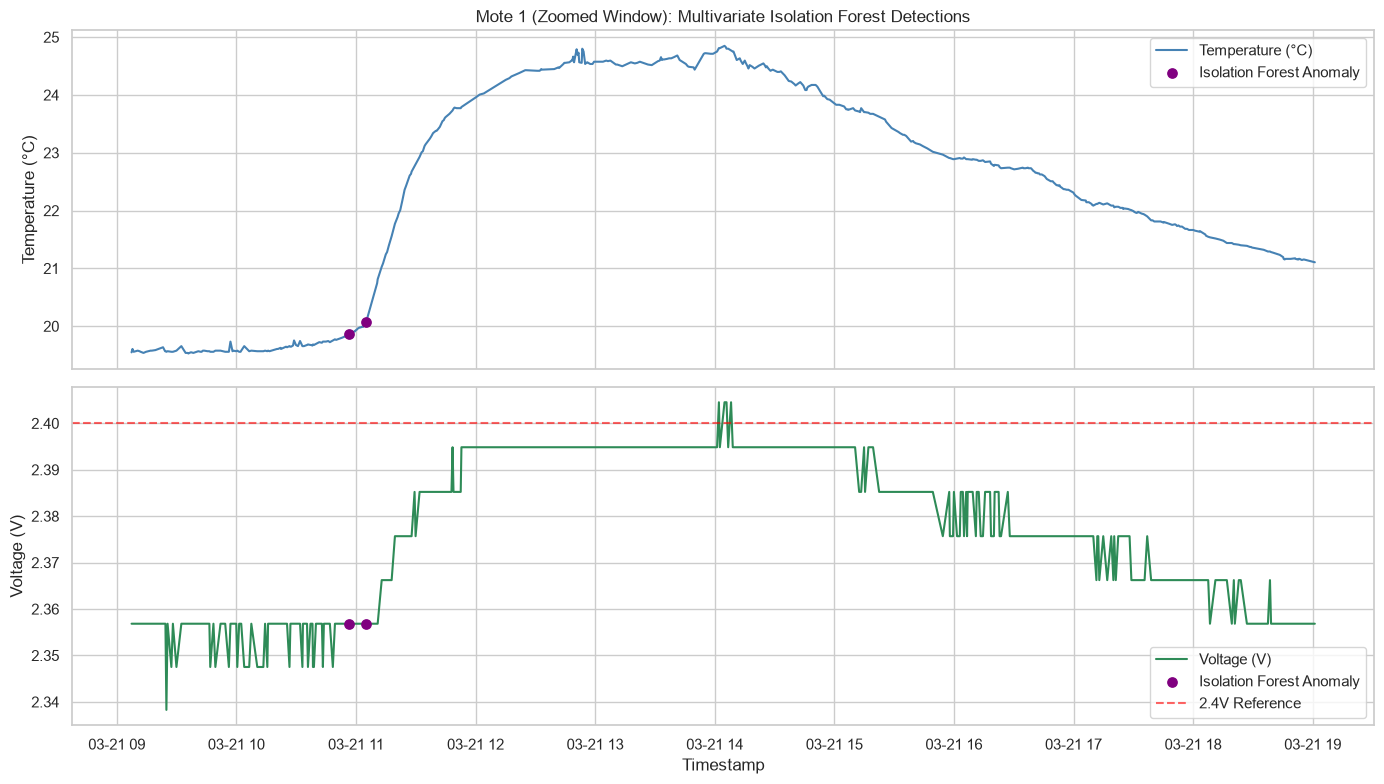

In [3]:
# 1. Quantify Overlap & Differences between Statistical (Z-Score) and ML (Isolation Forest)
z_only = (df_ml['is_z_anomaly'] & ~df_ml['anomaly_iforest']).sum()
if_only = (~df_ml['is_z_anomaly'] & df_ml['anomaly_iforest']).sum()
both = (df_ml['is_z_anomaly'] & df_ml['anomaly_iforest']).sum()

print("--- Detection Agreement Breakdown ---")
print(f"Caught by BOTH Z-Score & Isolation Forest : {both:,}")
print(f"Caught ONLY by Rolling Z-Score (Univariate): {z_only:,}")
print(f"Caught ONLY by Isolation Forest (Multivariate): {if_only:,}")

# 2. Properly time-sorted zoom-in plot for Mote 1 (around an anomaly cluster)
mote_sorted = df_ml[df_ml['moteid'] == 1].sort_values('timestamp').reset_index(drop=True)
# Pick a 500-reading slice that contains detected anomalies
anom_indices = mote_sorted[mote_sorted['anomaly_iforest']].index
start_idx = max(0, anom_indices[0] - 100) if len(anom_indices) > 0 else 0
mote_window = mote_sorted.iloc[start_idx : start_idx + 500]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(mote_window['timestamp'], mote_window['temperature'], color='steelblue', label='Temperature (°C)')
if_pts = mote_window[mote_window['anomaly_iforest']]
axes[0].scatter(if_pts['timestamp'], if_pts['temperature'], color='purple', label='Isolation Forest Anomaly', s=45, zorder=5)
axes[0].set_ylabel('Temperature (°C)')
axes[0].set_title('Mote 1 (Zoomed Window): Multivariate Isolation Forest Detections')
axes[0].legend()

axes[1].plot(mote_window['timestamp'], mote_window['voltage'], color='seagreen', label='Voltage (V)')
axes[1].scatter(if_pts['timestamp'], if_pts['voltage'], color='purple', label='Isolation Forest Anomaly', s=45, zorder=5)
axes[1].axhline(2.4, color='red', linestyle='--', alpha=0.6, label='2.4V Reference')
axes[1].set_ylabel('Voltage (V)')
axes[1].set_xlabel('Timestamp')
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Model Evaluation Metrics (Isolation Forest)
Because the Intel Berkeley Lab dataset does not contain ground-truth anomaly labels, we evaluate our **Isolation Forest** model using:
1. **Temporal Generalization (Train vs. Test Drift):** Comparing the anomaly detection rate in the first 70% training window against the unseen 30% test window to ensure stability over time.
2. **Decision Score Separation:** Measuring the margin between normal and anomalous isolation path scores (`decision_function`).
3. **Cross-Method Agreement (Isolation Forest vs. Per-Sensor IQR):** Comparing multivariate Isolation Forest detections against univariate per-sensor IQR flags.

In [6]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

features = ['temperature', 'humidity', 'light', 'voltage']

# 1. Run Isolation Forest & record both Predictions and Anomaly Scores
def evaluate_isolation_forest(group, contamination=0.02):
    valid_idx = group[features].dropna().index
    preds_series = pd.Series(False, index=group.index)
    scores_series = pd.Series(np.nan, index=group.index)
    
    if len(valid_idx) < 50:
        return pd.DataFrame({'anomaly_iforest': preds_series, 'iforest_score': scores_series})
        
    X = group.loc[valid_idx, features]
    split_point = int(len(X) * 0.7)  # Causal 70% split
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X.iloc[:split_point])
    X_all = scaler.transform(X)
    
    iso = IsolationForest(n_estimators=100, contamination=contamination, random_state=42)
    iso.fit(X_train)
    
    preds_series.loc[valid_idx] = (iso.predict(X_all) == -1)
    # Lower decision_function score = more anomalous
    scores_series.loc[valid_idx] = iso.decision_function(X_all)
    
    return pd.DataFrame({'anomaly_iforest': preds_series, 'iforest_score': scores_series})

if_results = df_ml.groupby('moteid', group_keys=False).apply(evaluate_isolation_forest)
df_ml['anomaly_iforest'] = if_results['anomaly_iforest']
df_ml['iforest_score'] = if_results['iforest_score']

# 2. Unsupervised Internal Metrics (Temporal Stability & Score Separation)
def get_split_rates(group):
    split = int(len(group) * 0.7)
    return pd.Series({
        'train_rate_%': group['anomaly_iforest'].iloc[:split].mean() * 100,
        'test_rate_%': group['anomaly_iforest'].iloc[split:].mean() * 100
    })

split_stats = df_ml.groupby('moteid').apply(get_split_rates)
normal_score_mean = df_ml.loc[~df_ml['anomaly_iforest'], 'iforest_score'].mean()
anom_score_mean = df_ml.loc[df_ml['anomaly_iforest'], 'iforest_score'].mean()

print("=== 1. UNSUPERVISED ISOLATION FOREST METRICS ===")
print(f"Total Multivariate Anomalies Flagged : {df_ml['anomaly_iforest'].sum():,} ({df_ml['anomaly_iforest'].mean()*100:.2f}%)")
print(f"Train Anomaly Rate (First 70%)       : {split_stats['train_rate_%'].mean():.2f}%")
print(f"Unseen Test Anomaly Rate (Last 30%)  : {split_stats['test_rate_%'].mean():.2f}%")
print(f"Temporal Rate Drift (|Test - Train|) : {abs(split_stats['test_rate_%'].mean() - split_stats['train_rate_%'].mean()):.2f}%")
print(f"Mean Normal Decision Score           : {normal_score_mean:.4f}")
print(f"Mean Anomaly Decision Score          : {anom_score_mean:.4f}")
print(f"Decision Score Separation Margin     : {normal_score_mean - anom_score_mean:.4f}\n")

# 3. Cross-Method Comparison with Per-Sensor IQR (if IQR column exists in df_ml)
iqr_cols = [c for c in df_ml.columns if 'iqr' in c.lower() and ('anomaly' in c.lower() or 'flag' in c.lower() or 'is_' in c.lower())]

if iqr_cols:
    y_iqr = df_ml[iqr_cols].any(axis=1).astype(int)
    y_if = df_ml['anomaly_iforest'].astype(int)
    
    both = ((y_iqr == 1) & (y_if == 1)).sum()
    if_only = ((y_iqr == 0) & (y_if == 1)).sum()
    iqr_only = ((y_iqr == 1) & (y_if == 0)).sum()

    comp_df = pd.DataFrame({
        'Comparison Metric': [
            'IQR Anomalies Detected (Univariate)',
            'Isolation Forest Anomalies (Multivariate)',
            'Consensus Overlap (Flagged by Both)',
            'Multivariate-Only Anomalies (Caught Only by IF)',
            'Agreement F1-Score (IF vs. IQR)',
            'Jaccard Similarity (IoU)'
        ],
        'Result': [
            f"{y_iqr.sum():,} ({y_iqr.mean()*100:.2f}%)",
            f"{y_if.sum():,} ({y_if.mean()*100:.2f}%)",
            f"{both:,}",
            f"{if_only:,}",
            f"{f1_score(y_iqr, y_if, zero_division=0):.4f}",
            f"{jaccard_score(y_iqr, y_if, zero_division=0):.4f}"
        ]
    })
    print("=== 2. ISOLATION FOREST VS. PER-SENSOR IQR COMPARISON ===")
    display(comp_df)

=== 1. UNSUPERVISED ISOLATION FOREST METRICS ===
Total Multivariate Anomalies Flagged : 196,542 (8.53%)
Train Anomaly Rate (First 70%)       : 5.24%
Unseen Test Anomaly Rate (Last 30%)  : 15.89%
Temporal Rate Drift (|Test - Train|) : 10.64%
Mean Normal Decision Score           : 0.1057
Mean Anomaly Decision Score          : -0.0372
Decision Score Separation Margin     : 0.1428

=== 2. ISOLATION FOREST VS. PER-SENSOR IQR COMPARISON ===


,Comparison Metric,Result
0,IQR Anomalies Detected (Univariate),"74,468 (3.23%)"
1,Isolation Forest Anomalies (Multivariate),"196,542 (8.53%)"
2,Consensus Overlap (Flagged by Both),"51,750"
3,Multivariate-Only Anomalies (Caught Only by IF),"144,792"
4,Agreement F1-Score (IF vs. IQR),0.3819
5,Jaccard Similarity (IoU),0.2360


Saved Data/final_sensor_reliability_report.csv!


,moteid,x,y,total_readings,iforest_anomaly_%,avg_voltage,final_reliability_%
47,48,35.5,10,58226,7.02,2.55,86.24
46,47,39.5,14,57201,6.31,2.53,84.64
44,45,37.5,19,53245,6.68,2.56,83.62
30,31,15.5,28,65693,8.78,2.48,83.37
21,22,1.5,23,60165,11.83,2.50,81.51
22,23,6.0,24,62440,7.40,2.48,80.87
20,21,4.5,18,58525,7.29,2.52,80.42
6,7,22.5,8,55361,7.80,2.50,77.78
28,29,12.5,26,64391,11.10,2.43,77.50
35,36,26.5,31,57743,6.87,2.48,77.31


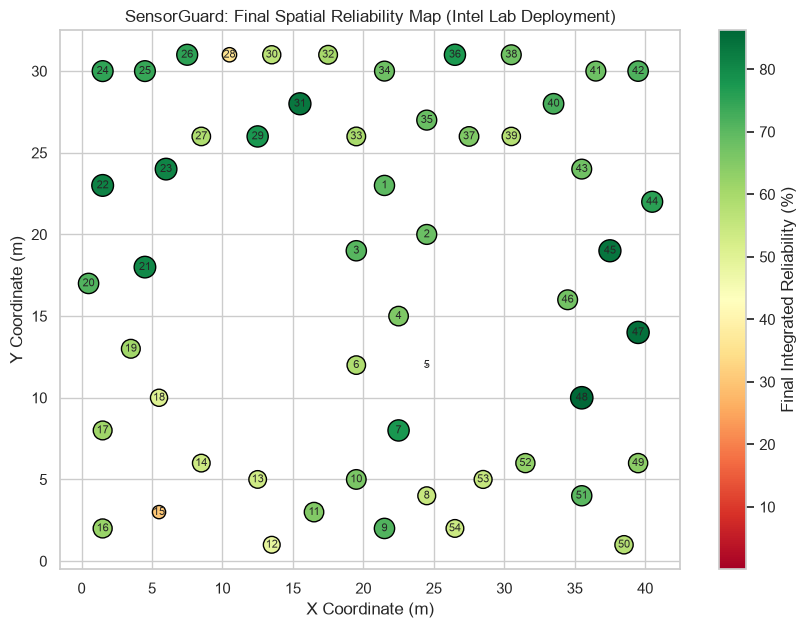

In [8]:
# Final Integrated Sensor Reliability Index (Data Quality + Isolation Forest)
max_epochs = df_ml['epoch'].max()
final_summary = []

for moteid, group in df_ml.groupby('moteid'):
    total_readings = len(group)
    completeness = min(total_readings / max_epochs, 1.0)
    
    # Valid ratio accounting for Isolation Forest multivariate anomalies & low voltage
    clean_ratio = (~group['anomaly_iforest'] & (group['voltage'] >= 2.4)).mean()
    
    # Composite Reliability Score (0 - 100%)
    reliability_score = (0.5 * completeness + 0.5 * clean_ratio) * 100
    
    final_summary.append({
        'moteid': int(moteid),
        'x': group['x'].iloc[0],
        'y': group['y'].iloc[0],
        'total_readings': total_readings,
        'iforest_anomaly_%': round(group['anomaly_iforest'].mean() * 100, 2),
        'avg_voltage': round(group['voltage'].mean(), 2),
        'final_reliability_%': round(reliability_score, 2)
    })

df_final_rel = pd.DataFrame(final_summary).sort_values('final_reliability_%', ascending=False)

# Save final reliability report to CSV for your project deliverables
df_final_rel.to_csv('Data/final_sensor_reliability_report.csv', index=False)
print("Saved Data/final_sensor_reliability_report.csv!")
display(df_final_rel.head(10))

# Final Spatial Map of Network Reliability
plt.figure(figsize=(10, 7))
sc = plt.scatter(df_final_rel['x'], df_final_rel['y'], c=df_final_rel['final_reliability_%'],
                 cmap='RdYlGn', s=df_final_rel['final_reliability_%']*3, edgecolors='black')
plt.colorbar(sc, label='Final Integrated Reliability (%)')
for _, r in df_final_rel.iterrows():
    plt.annotate(str(int(r['moteid'])), (r['x'], r['y']), fontsize=8, ha='center', va='center')
plt.title("SensorGuard: Final Spatial Reliability Map (Intel Lab Deployment)")
plt.xlabel("X Coordinate (m)")
plt.ylabel("Y Coordinate (m)")
plt.show()